# Data Visualization in Python

Hello-Hello! In this workshop we will have a look at the loan approval data. Before building any models, we need to ensure that we can understnad the data. Maybe some insights can be gained just from looking at the data visuals?

The process of looking at the data, summarising and plotting it is called **Exploratory Data Analysis (EDA)**. This is usually the first step in building a Machine Learning model because it helps us spot inconsistencies and mistakes and data find patterns and generally decide what methods are appropriate.

# Dataset Description


This dataset contains financial and demographic information on 1,000 loan applicants, designed to facilitate the development of machine learning models for credit risk assessment and loan approval prediction. It includes key features such as annual income, credit score, loan amount, number of dependents, and employment status

Source: https://www.kaggle.com/datasets/amineipad/loan-approval-dataset?resource=download


# Goal of today's workshop

By the end of this workshop you should be familiar with the plots that you could build with the seaborn library. We will also try to answer the following questions:


1. What factors affect the most significantly on the decision wether a certain individual will get the loan approved or not?

2. How the data is distributed

# 0 Libraries set up and data loading

Python on its own has only basic features. **Libraries** are collections of ready-made tools that we *import*. We give each one a short nickname (an *alias*) so we type less

More about libraries: [what is a python library](https://www.codegenes.net/blog/what-is-a-python-library/)

Sometimes you need to install the libraries using `pip install` in the terminal but they are already pre-installed in the colab. We just need to import them



In [6]:
import pandas as pd              # To work with tabular data (tables)
import matplotlib.pyplot as plt  # To plot basic graphs
import seaborn as sns            # Advanced version of matplotlib, enables more advanced plotting
import numpy as np               # To work with numerical data (arrays)

In [204]:
df= pd.read_csv("https://github.com/sheffdatasoc/2026-27/blob/main/Seaborn%20data%20visualisation%20with%20python/loanapproval.csv?raw=true")

In [7]:
# df = pd.read_csv("/content/loanapproval.csv") # backup in case if the github line will not work

# 1 INFO FROM LOOKING AT THE TABLE USING `pandas`

Before drawing any plots we need to know **what is in the table** and **how clean** is our data

*(spoiler: this dataset is very clean)*

Lets try to answer the following questions:

* How many rows and columns are there?
* What does each column contain (numbers? text?)
* Are there **missing values** or **duplicated rows**?
* How many different values does each column have?


let's start from using `df.head()` and `df.tail()` to get a general idea of what rows and columns we have in teh dataset


In [170]:
df # display data (note: in code editor to display the variable you will need to type `print(df)`)

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,1,59,Male,Divorced,100073,7169,793,1,1,Unemployed,1
1,2,49,Male,Married,112197,23556,789,0,2,Employed,1
2,3,35,Male,Divorced,84429,27052,372,1,4,Unemployed,0
3,4,63,Female,Single,124195,11313,808,3,4,Self-employed,1
4,5,28,Female,Married,81627,13315,689,0,1,Unemployed,1
...,...,...,...,...,...,...,...,...,...,...,...
995,996,53,Female,Married,135598,6014,767,3,2,Employed,1
996,997,22,Male,Single,139028,15103,662,0,0,Self-employed,1
997,998,34,Female,Married,147517,21986,582,0,2,Employed,1
998,999,60,Female,Divorced,73161,49781,635,4,0,Unemployed,1


In [171]:
df.head() # first 5 rows of the data

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,1,59,Male,Divorced,100073,7169,793,1,1,Unemployed,1
1,2,49,Male,Married,112197,23556,789,0,2,Employed,1
2,3,35,Male,Divorced,84429,27052,372,1,4,Unemployed,0
3,4,63,Female,Single,124195,11313,808,3,4,Self-employed,1
4,5,28,Female,Married,81627,13315,689,0,1,Unemployed,1


In [172]:
df.tail() # last 5 rows of the dataset

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
995,996,53,Female,Married,135598,6014,767,3,2,Employed,1
996,997,22,Male,Single,139028,15103,662,0,0,Self-employed,1
997,998,34,Female,Married,147517,21986,582,0,2,Employed,1
998,999,60,Female,Divorced,73161,49781,635,4,0,Unemployed,1
999,1000,60,Female,Single,141316,35471,461,1,1,Unemployed,1


In [173]:
df.head(10) # first 10 rows of the data

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved
0,1,59,Male,Divorced,100073,7169,793,1,1,Unemployed,1
1,2,49,Male,Married,112197,23556,789,0,2,Employed,1
2,3,35,Male,Divorced,84429,27052,372,1,4,Unemployed,0
3,4,63,Female,Single,124195,11313,808,3,4,Self-employed,1
4,5,28,Female,Married,81627,13315,689,0,1,Unemployed,1
5,6,41,Male,Married,53848,13036,594,3,4,Unemployed,0
6,7,59,Male,Divorced,57804,36778,668,1,1,Employed,1
7,8,39,Male,Single,35379,32734,848,0,4,Unemployed,0
8,9,43,Female,Married,79664,28173,486,1,0,Employed,1
9,10,31,Female,Single,47766,35403,744,0,1,Self-employed,1


In [12]:
df.head(0) # display only the headings

,applicant_id,age,gender,marital_status,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,employment_status,loan_approved


Now let's have a look at the built-in pandas methods that can help us describe a dataset

In [13]:
# Actually, applicant id is just an identifier and we don't need it. uncomment the two following lines to let's drop it
# df.drop(columns=["applicant_id"], inplace=True)
# df.head()

In [14]:
df.info() # get information about the columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   applicant_id          1000 non-null   int64 
 1   age                   1000 non-null   int64 
 2   gender                1000 non-null   object
 3   marital_status        1000 non-null   object
 4   annual_income         1000 non-null   int64 
 5   loan_amount           1000 non-null   int64 
 6   credit_score          1000 non-null   int64 
 7   num_dependents        1000 non-null   int64 
 8   existing_loans_count  1000 non-null   int64 
 9   employment_status     1000 non-null   object
 10  loan_approved         1000 non-null   int64 
dtypes: int64(8), object(3)
memory usage: 86.1+ KB


In [15]:
df.describe().T # get statistical information about the columns

# df.describe().T transposes the table to swap rows and columns

,count,mean,std,min,25%,50%,75%,max
applicant_id,1000.0,500.500,288.819436,1.0,250.75,500.5,750.25,1000.0
age,1000.0,42.515,12.611059,21.0,32.00,43.0,53.00,64.0
annual_income,1000.0,81972.972,37547.255418,20155.0,48913.25,82050.0,113556.00,149951.0
loan_amount,1000.0,27244.866,12822.752877,5082.0,16587.50,27041.5,37939.25,49864.0
credit_score,1000.0,576.125,155.921483,300.0,443.75,573.5,713.25,849.0
num_dependents,1000.0,1.977,1.418620,0.0,1.00,2.0,3.00,4.0
existing_loans_count,1000.0,2.042,1.413589,0.0,1.00,2.0,3.00,4.0
loan_approved,1000.0,0.729,0.444699,0.0,0.00,1.0,1.00,1.0


In [16]:
df.describe(include="object") # we can also include the text data

,gender,marital_status,employment_status
count,1000,1000,1000
unique,2,3,3
top,Male,Married,Self-employed
freq,524,355,350


How to interpret:

`df.info()` lists each column with its **data type** (`dtype`) and how many **non-null** (not missing) values it has



*   `<class 'pandas.core.frame.DataFrame'>` just tells us that the whole variable `df` is a `DataFrame` class
*   `RangeIndex: 1000 entries, 0 to 999` tells us that there are 1000 rows qith index starting from 0 (not 1)
* `Non-Null Count` column tells us that all 1000 columns have non-empty values --> no missing values in this dataset (yaay!!!)
* `Dtype` data type
  * `int64` = whole numbers,
  * `float64` = decimal numbers
  * `object` = text
  * more on pandas dtypes and their variations can be found [here](https://www.statology.org/pandas-dtypes/)




  



`df.describe()` tells us the **statistical information** about **numerical** columns (cannot do statistics with text so it doesn't return anything for the columns that contain text)
* `count`: total number of non-null entries in each column
* `mean`: average (mean) of the values in the column
* `std`: standard deviation showing how spread out the values are
* `min`: minimum value in the column
* `25%`: the 25th percentile (Q1) which means 25% of the data points are less than this value.
* `50%`: median value (50th percentile) where half the data points are below it.
* `75%`: the 75th percentile (Q3) means 75% of the data points are below this value.
* `max`: maximum value in the column.

Source: https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-describe-method/

Useful statistical resources:
- https://www.statology.org/a-simple-explanation-of-how-to-interpret-variance/
- understand quartiles: https://www.investopedia.com/terms/q/quartile.asp (I had troubles with them so this is what helped me)




Common questions:


* Q: Uhhhm but [built-in python data types](https://www.w3schools.com/python/python_datatypes.asp) are int, float, str etc, why the data types from the DataFrame look difefrent and why text is classified as an object data type and not str?

  * A: according to [this post](https://stackoverflow.com/questions/21018654/strings-in-a-dataframe-but-dtype-is-object), it is because the pandas is built using library requiring that all elements has the same size. String can be different and can have various size so it is being replaced with pointers to the objects #TODO: CHECK THIS CALIM




Let's check if there are any duplications or inacurracies in our dataset

In [17]:
df.duplicated().sum() # number of all duplicate rows

np.int64(0)

In [18]:
df.nunique() # number of all unique values

,0
applicant_id,1000
age,44
gender,2
marital_status,3
annual_income,996
loan_amount,990
credit_score,452
num_dependents,5
existing_loans_count,5
employment_status,3


**Categorical, Discrete and Continuous Variables**



*   **Categorical**: label that can be used to group data, usually comes in the form of text (e.g. gender or employment status)
*   **Discrete**: separate, countable values, usually the number unique values of these variables is smaller than the number of rows in the dataset (e.g. num_dependents)
* **Continuous**: variables that take bunch of values within the given range, usully number of values of these variables is close to the number of rows in the dataset (e.g. annual_income)





---



Your turn:

What type of variables do all of these columns have?



---




In [19]:
# split the dataframe into the numerical variables and categorical
df_num = df[['age', 'annual_income', 'loan_amount', 'credit_score', 'num_dependents', 'existing_loans_count', 'loan_approved']]
df_cat = df[['gender', 'marital_status', 'employment_status']]



---



**Your turn**: display first 10 rows of `df_num` and last 10 rows of `df_cat`

In [20]:
# first 10 rows of df_num

In [21]:
# last 10 rows of df_cat



---



# 2 CORRELATION MATRIX AND HEATMAP

The **(Pearson) correlation coefficient**, *r*, measures how strongly two numerical variables move together **in a straight line**:

* **r = +1**: perfect positive relationship (when one goes up, the other goes up)
* **r = −1**: perfect negative relationship (when one goes up, the other goes down)
* **r = 0**: no *linear* relationship

A rough rule of thumb: |r| < 0.1 negligible, 0.1–0.3 weak, 0.3–0.5 moderate, > 0.5 strong.

In [22]:
corr = df_num.corr() # correlation matrix
corr

,age,annual_income,loan_amount,credit_score,num_dependents,existing_loans_count,loan_approved
age,1.000000,0.002591,0.000235,0.052769,-0.031510,0.063977,0.020984
annual_income,0.002591,1.000000,-0.024862,0.016921,-0.016445,-0.010745,0.176453
loan_amount,0.000235,-0.024862,1.000000,0.044939,0.037140,-0.012043,0.015355
credit_score,0.052769,0.016921,0.044939,1.000000,-0.067063,0.017398,0.351167
num_dependents,-0.031510,-0.016445,0.037140,-0.067063,1.000000,0.046405,-0.365317
existing_loans_count,0.063977,-0.010745,-0.012043,0.017398,0.046405,1.000000,-0.324236
loan_approved,0.020984,0.176453,0.015355,0.351167,-0.365317,-0.324236,1.000000


<Axes: >

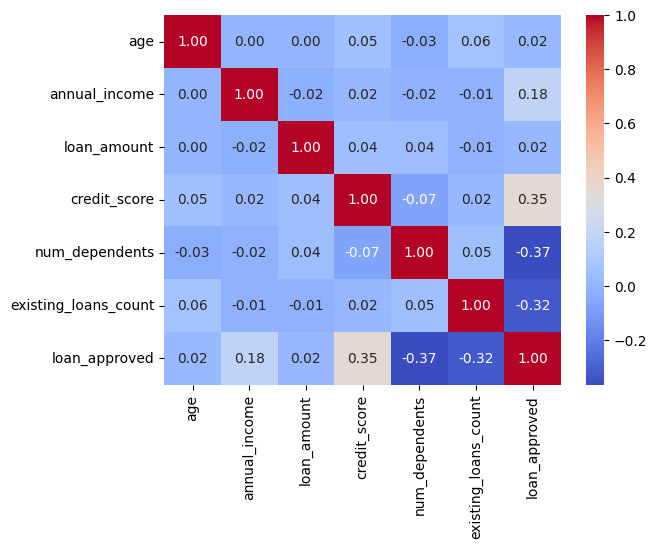

In [23]:
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")


Good but can we make it better?

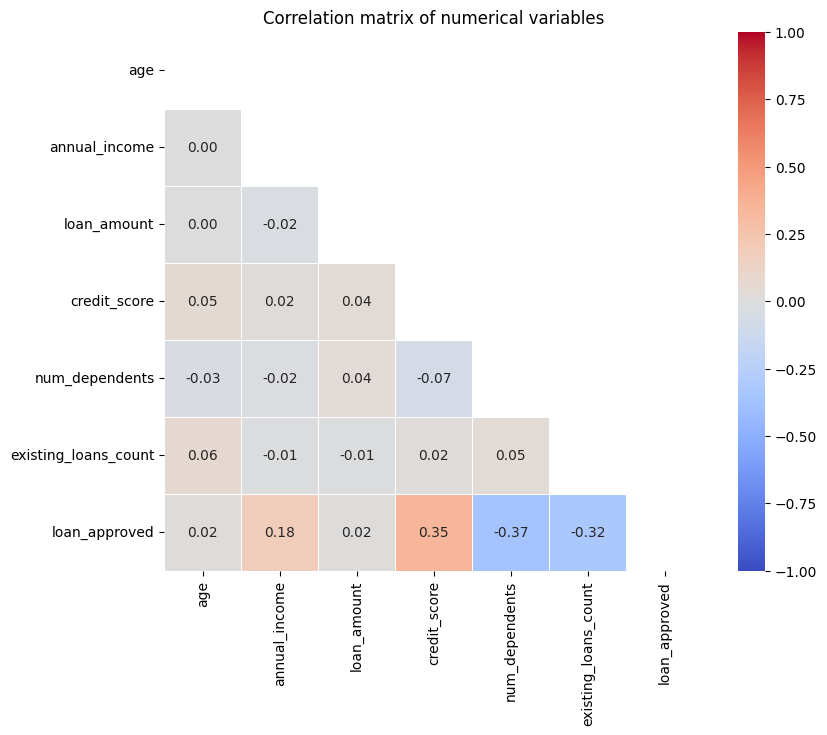

In [24]:
mask = np.triu(np.ones_like(corr, dtype=bool))   # True for the upper triangle

plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap = 'coolwarm',
            vmin = -1, vmax = 1, center = 0,
            annot=True, fmt=".2f", square=True,
            linewidths=.5, mask = mask)
plt.title("Correlation matrix of numerical variables")
plt.show()

More about the seaborn heatmaps: https://www.datacamp.com/tutorial/seaborn-heatmaps

# 2 WORKING WITH CATEGORICAL DATA



So far our correlation matrix ignored `gender`, `marital_status` and `employment_status` because they are **text**. Categorical plots show how a numerical variable (or a count) **differs between categories**. Seaborn groups them into three families:

| Family | Functions | Shows |
|---|---|---|
| **Categorical Estimates** | `countplot`, `barplot`, `pointplot` | counts, means and confidence intervals |
| **Categorical Distributions** | `boxplot`, `violinplot`, `boxenplot` | the spread of values in each category |
| **Categorical scatterplots** | `stripplot`, `swarmplot` | every single data point |

## 2.1 Categorical estimates

### 2.1.1 Countplots `sns.countplot()`

Before we proceed, we need to answer one question: "Who is Hue and why she is always in your plots?"


Good question, let's try to plot a number of loans approved and see what the data can tell us



<Axes: xlabel='loan_approved', ylabel='count'>

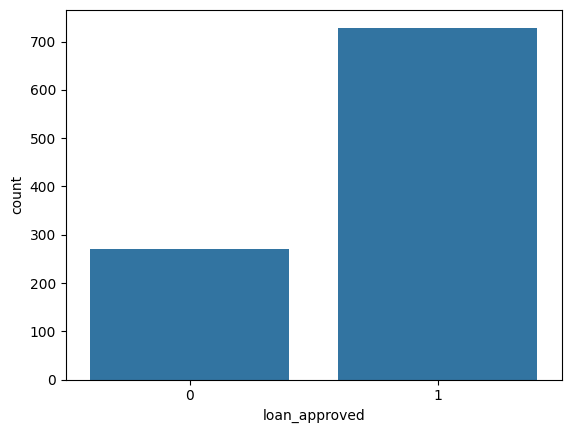

In [25]:
sns.countplot(data=df, x='loan_approved')

Aha! We know that banks are more likely to approve the loan. But how about categories? Are women more likely to get approved for a loan rather than men? What about their employment status? Does being married affect it?


This is where **hue** comes to help. It helps us categorise the data and show different categories within the dataset.

<Axes: xlabel='loan_approved', ylabel='count'>

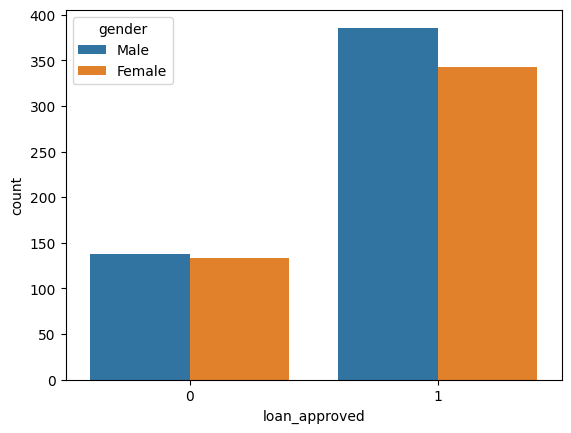

In [26]:
sns.countplot(data=df, x="loan_approved", hue="gender")




How about other categories?



---



**Your turn**: change the code to display the countplots grouped by `gender`, `marital_status` and `employment_status`

ValueError: Could not interpret value `____` for `hue`. An entry with this name does not appear in `data`.

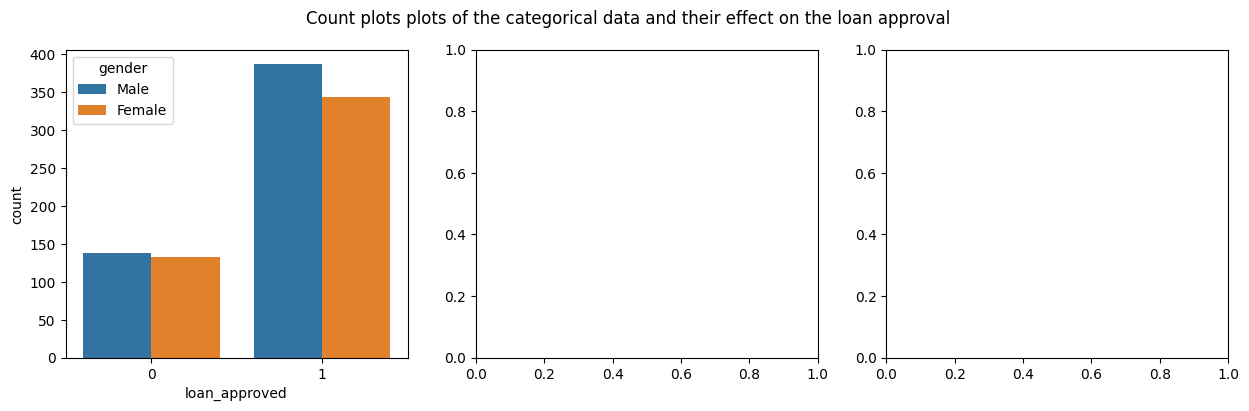

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4)) # this line is needed to plot all three subplots on a single figure
fig.suptitle('Count plots plots of the categorical data and their effect on the loan approval') # setting up the title

sns.countplot(ax=axes[0], data=df, x='loan_approved', hue='gender') # this is a plot we used as an example

sns.countplot(ax=axes[1], data=df, x='loan_approved', hue='____') # edit this line to group by marital_status
sns.countplot(ax=axes[2], data=___, x='_____', hue='_____') # edit this line to group by employment_status

plt.tight_layout()
plt.show



---



Sooo we can say that men are more likely to get approved, as well as married people and self emplyed people?

Nice! Our work is done, analysis is finished, we are perfect. Oh wait...

*Some groups can have more applicants than other!!!!!*.

In other words, if our dataset is imbalanced, we could make false conclusions since count plot just counts the number of values.


Let's put the numbers side by side in a table. For each group we calculate:
* `applicants`: how many people applied
* `approved`: how many were approved
* `approval_rate`: **approved ÷ applicants**, the *proportion* of the group that was approved

The **approval rate** removes the effect of group size, so we can compare groups **fairly**

In [28]:
for col in df_cat:
    summary = df.groupby(col).agg(
        applicants=("loan_approved", "count"),   # how many rows in each group
        approved=("loan_approved", "sum"),       # how many 1s (approvals)
    )
    summary["rejected"] = summary["applicants"] - summary["approved"]
    summary["approval_rate"] = (summary["approved"] / summary["applicants"]).round(3)
    display(summary)

,applicants,approved,rejected,approval_rate
gender,,,,
Female,476,343,133,0.721
Male,524,386,138,0.737


,applicants,approved,rejected,approval_rate
marital_status,,,,
Divorced,303,217,86,0.716
Married,355,272,83,0.766
Single,342,240,102,0.702


,applicants,approved,rejected,approval_rate
employment_status,,,,
Employed,320,261,59,0.816
Self-employed,350,299,51,0.854
Unemployed,330,169,161,0.512


### 2.1.2 Barplots `sns.barplot()`


`barplot()` shows the **mean** of a numerical variable for each category, plus an **error bar** (the 95 % confidence interval by default). Using `y="loan_approved"` gives the **approval rate** per category (see how we calculated this value above)

<Axes: xlabel='gender', ylabel='loan_approved'>

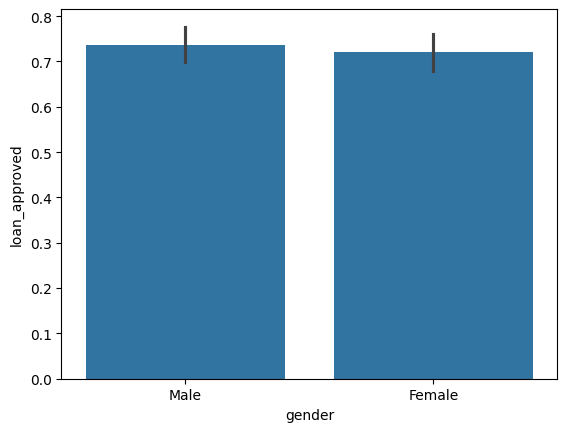

In [29]:
sns.barplot(data=df, y="loan_approved", x="gender") # note how we swapped x and y here to still create vertical bars
# sns.barplot(data=df, y="loan_approved", x="gender", hue="gender") # uncomment this to use effect of still groupping it by gender

Text(0, 0.5, 'Approval rate')

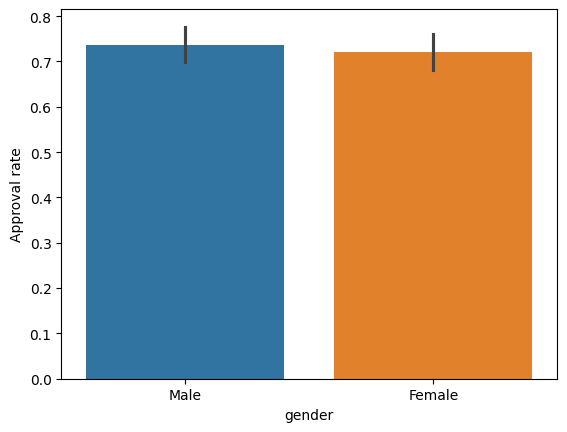

In [30]:
# One step up: let's rename the y label from loan_approved to approval rate
ax = sns.barplot(data=df, y="loan_approved", x="gender", hue="gender")
ax.set_ylabel("Approval rate")



---
**Your turn**: create a barplots with the approval rate for all categorical values (`gender`, `marital_status` and `employment_status`)



In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True) # this line is needed to plot all three subplots on a single figure, sharey=True means that all subplots will share the same vertical axis
fig.suptitle('Approval rate for the categorical variables') # setting up the title

sns.barplot(ax=axes[0], data=df, y="loan_approved", x="gender", hue="gender") # this is a plot we used as an example

sns.barplot(ax=axes[1], data=df, y="loan_approved", x="____", hue="_____") # edit this line to group by marital_status
sns.barplot(ax=axes[2], data=__, y="___", x="_____", hue="____") # edit this line to group by employment_status

axes[0].set_ylabel("______")
plt.tight_layout()
plt.show()

**Your turn (extra hard)**: create a barplot with approval rate for `gender` category, groupped by `marital_status`

In [ ]:
### write your code here







---



**Rule of thumb**
> Use **counts** to describe the data ("how many people are in each group?").

> Use **rates** to compare outcomes ("is this group more likely to be approved?")

### 2.1.3 pointplots `sns.pointplot()`

A point plot shows the same information as a bar plot, but as **points connected by lines**. This makes it easy to compare **interactions**: how the effect of one variable changes across the levels of another

Let's create the point plot that shows the loan approval rate in comparison to number of `existing_loans_count` and groupped by `employment_rate`

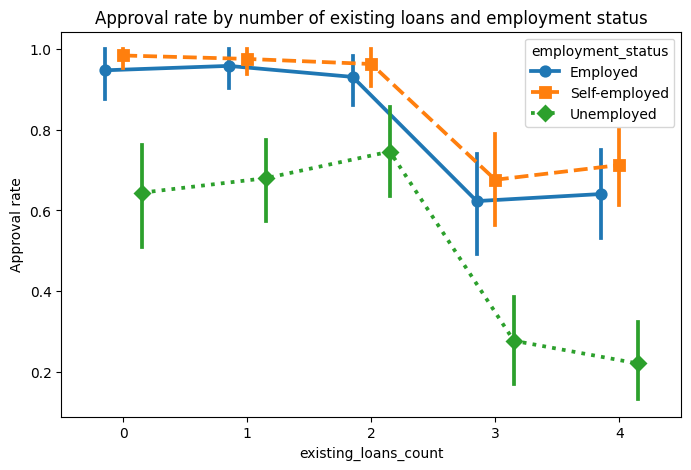

In [31]:
plt.figure(figsize=(8, 5))

sns.pointplot(data=df, x="existing_loans_count", y="loan_approved",
              hue="employment_status", dodge=0.3, markers=["o", "s", "D"], linestyles=["-", "--", ":"])

plt.ylabel("Approval rate")
plt.title("Approval rate by number of existing loans and employment status")
plt.show()

How to interpret: All three lines show the same **drop at 3+ existing loans**, and the Unemployed line is lower everywhere. The two risk factors **reinforce each other**, e.g. for unemployed applicants the drop is even steeper, from about 70 % to only about **25 %** with 3+ loans.



---




**Your turn**: Create the point plot that shows the loan approval rate in comparison to `num_dependents` count and groupped by employment rate

*Note: you might want to use `hue_order=["Employed", "Unemployed", "Self-employed"]` argument to ensure that the legend is ordered in the same way as on the line plot above

In [ ]:
# Write your code here





---



## 2.2 Categorical Distributions

### 2.2.1 Boxplots `sns.boxplot()`

A **box plot** summarises a distribution with five numbers:
* the **box** goes from the 25th to the 75th percentile (the middle 50 % of the data);
* the **line inside** the box is the **median**;
* the **whiskers** extend to the most extreme values within 1.5 × the box height;
* **dots** beyond the whiskers are potential **outliers**.

<Axes: xlabel='loan_approved', ylabel='age'>

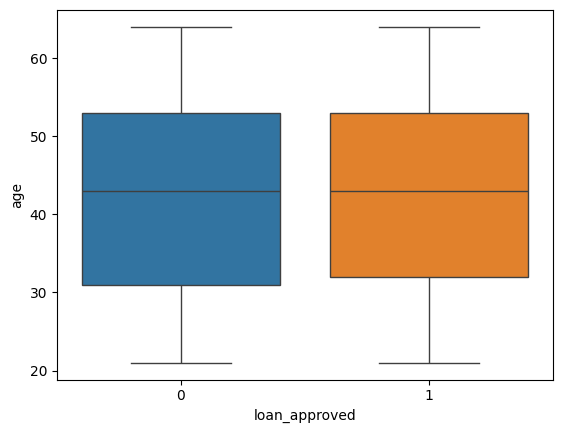

In [32]:
sns.boxplot(data=df, x='loan_approved', y='age', hue="loan_approved", legend=False)

**Your turn**: plot boxplots for loan_approval for all numerical continuous variables (`age`, `annual_income`, `loan_amount`, `credit_score`)

ValueError: Could not interpret value `____` for `y`. An entry with this name does not appear in `data`.

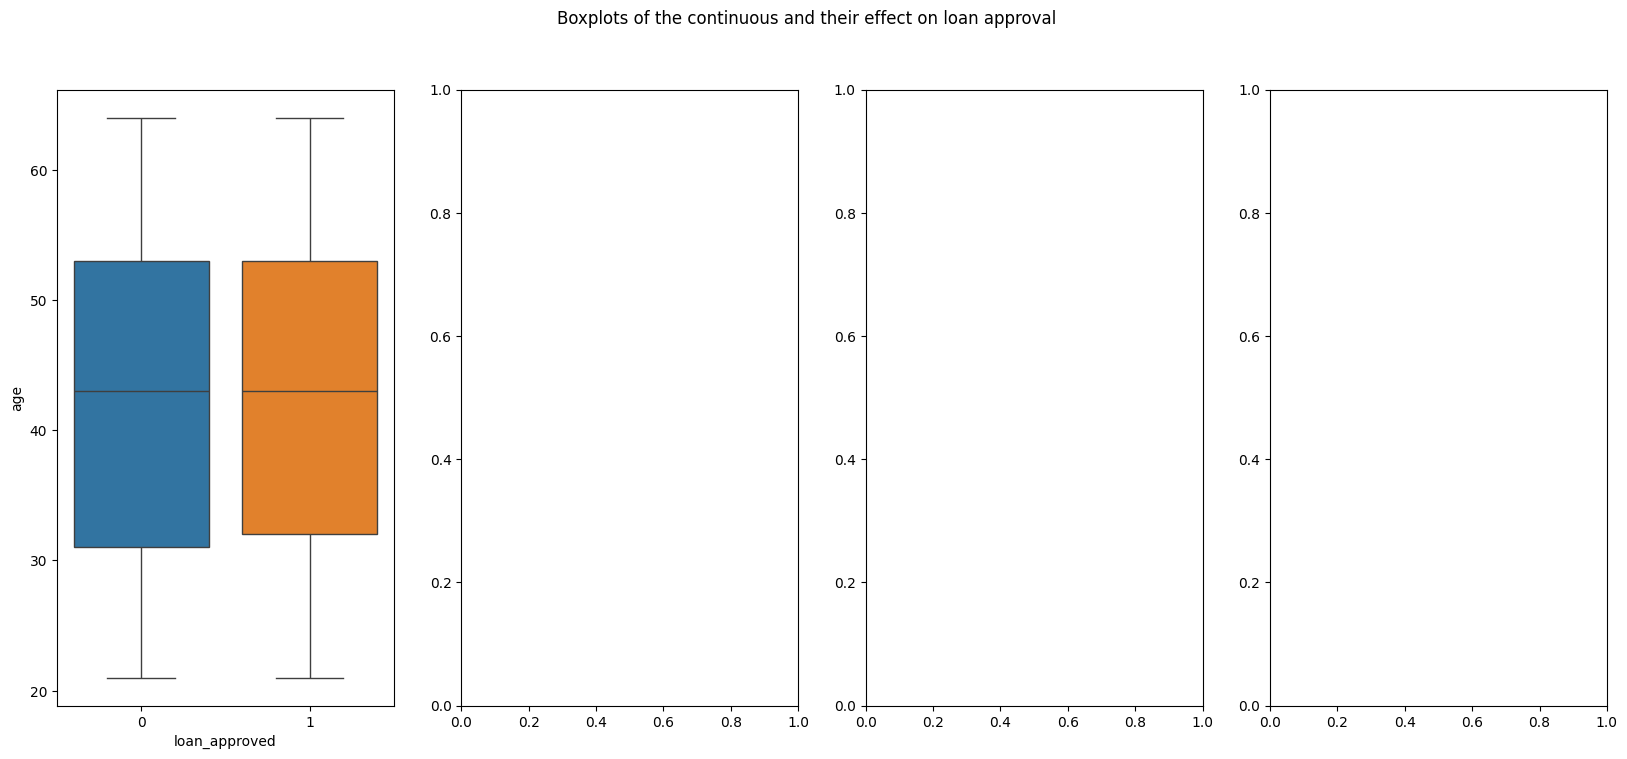

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(20, 8))
fig.suptitle('Boxplots of the continuous and their effect on loan approval')

sns.boxplot(ax=axes[0], data=df, x='loan_approved', y='age', hue="loan_approved", legend=False) # age
sns.boxplot(ax=axes[1], data=df, x='loan_approved', y='____', hue="loan_approved", legend=False) # annual_income
sns.___(ax=axes[2], data=df, x='___', y='___', hue="_____", legend=___) #loan_amount
# write here line to build a boxplot for the credit_score


plt.tight_layout()
plt.show()

---

Quite tedious. Well, good that we can run the for loop to plot our graphs

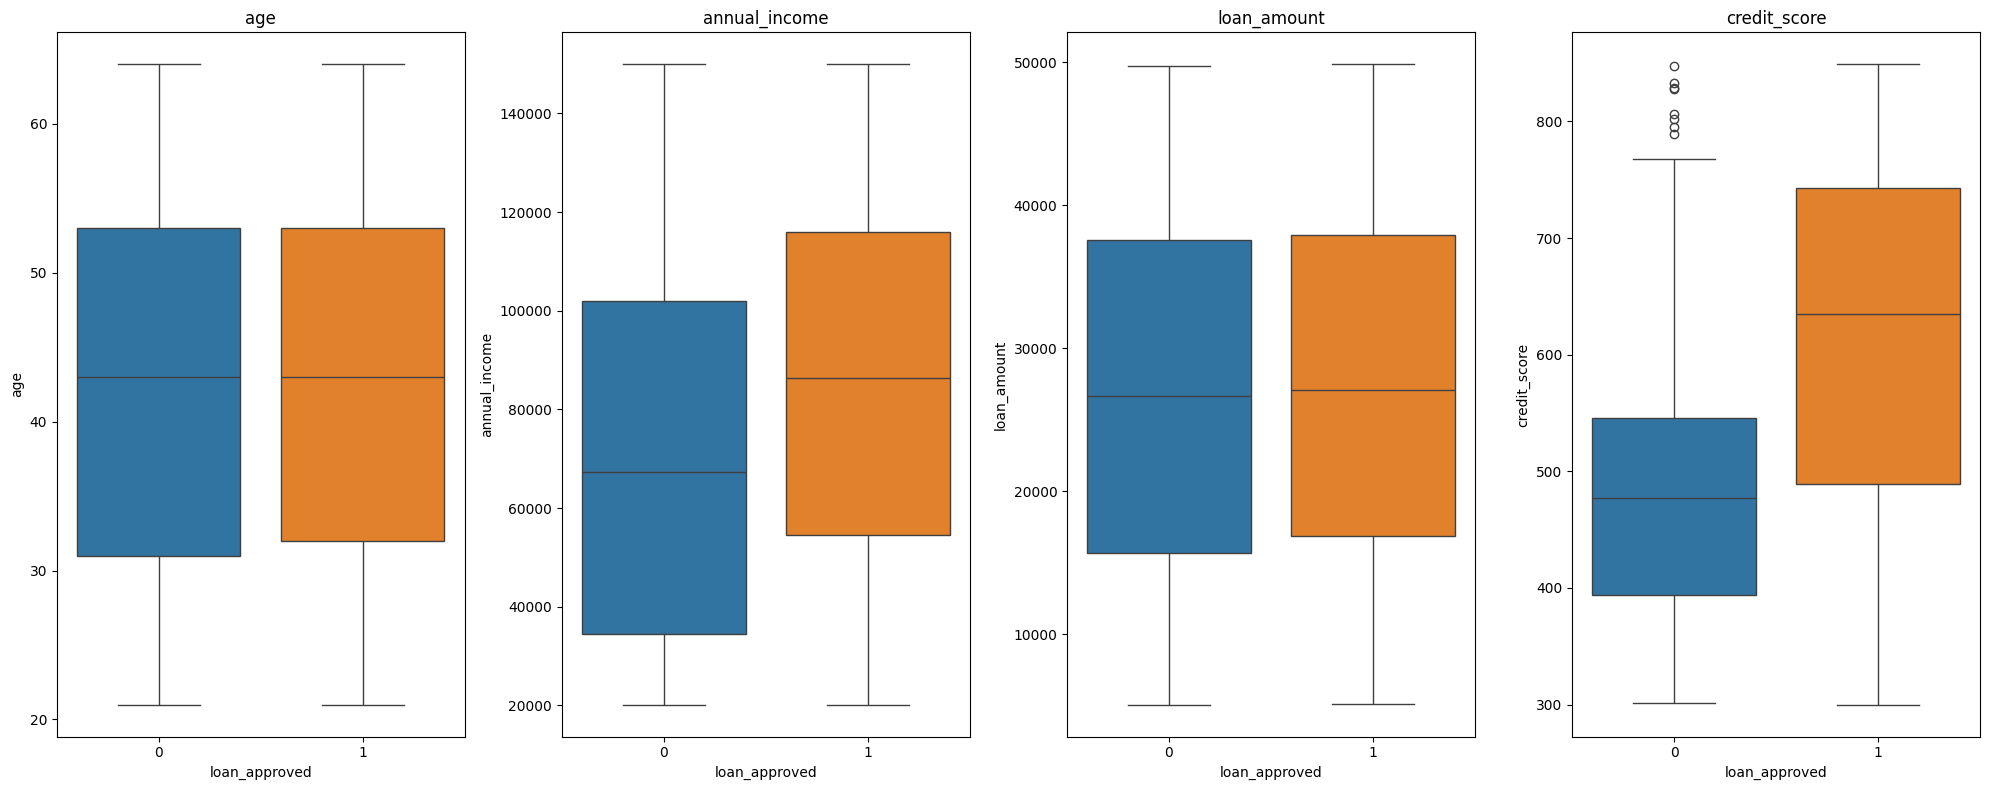

In [34]:
df_continuous = ["age", "annual_income", "loan_amount", "credit_score"] # all continuous variables

fig, axes = plt.subplots(1, 4, figsize=(20, 8))

for ax, col in zip(axes, df_continuous):
    sns.boxplot(data=df, x="loan_approved", y=col, hue="loan_approved", ax=ax, legend=False)
    ax.set_title(col)

plt.tight_layout()
plt.show()

### 2.2.2 `sns.violinplot()`

With this type of plot you can see the full shape of the distribution. With `hue` and `split=True`, each half of the violin shows one group, so they're easy to compare.
`inner="quart"` draws dashed lines at the quartiles.

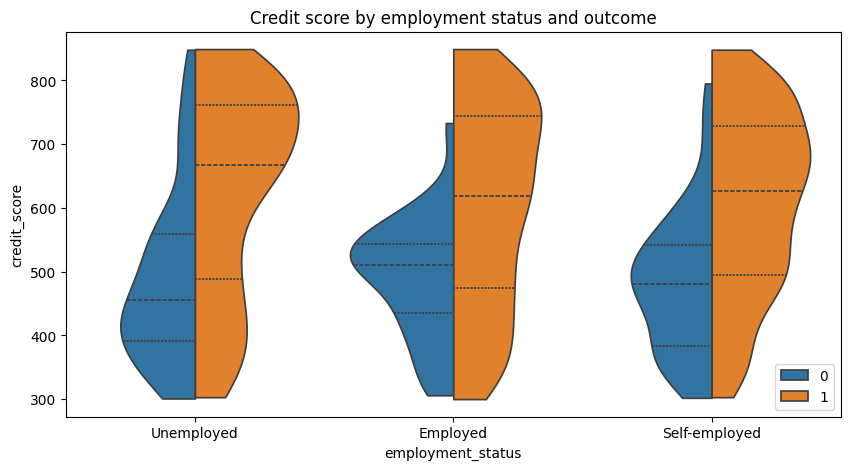

In [149]:
plt.figure(figsize=(10, 5))
sns.violinplot(data=df, x="employment_status", y="credit_score", hue="loan_approved",
               split=True, inner="quart", cut=0)

plt.legend(loc="lower right")
plt.title("Credit score by employment status and outcome")
plt.show()

How to interpret: In every group the rejected half (blue) sits **lower** than the approved half, so credit score matters for everyone. But look at the **top** of the blue halves: for Employed applicants rejections stop at about 730, and for Self-employed at about 800. For **Unemployed** applicants the orange half reaches all the way up to **850**. hence, even an excellent credit score does not guarantee approval when you are unemployed.


**Your turn**: Plot the similar plot but compare `num_dependents` and `annual_income`, group by `loan_approved`

---



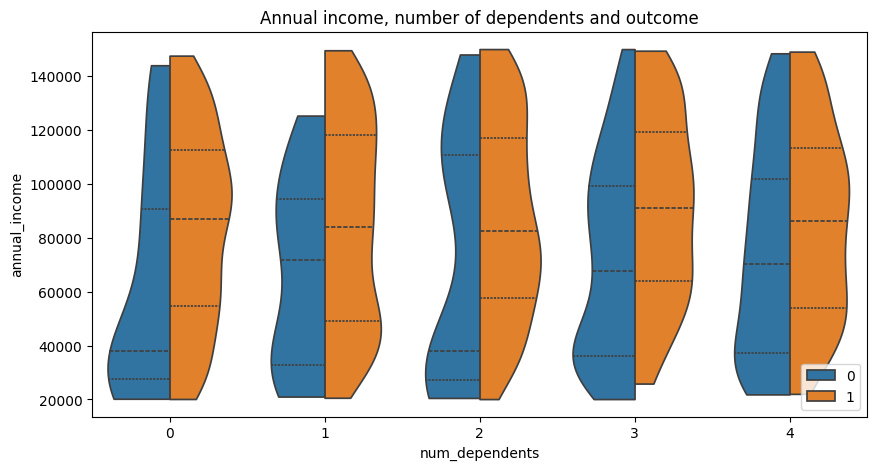

In [36]:
plt.figure(figsize=(10, 5))
sns.___(data=df, x="___", y="___", ___="___",
               split=True, inner="quart", cut=0)

plt.legend(loc="lower right")
plt.title("Annual income, number of dependents and outcome")
plt.show()

---

### 2.2.3 boxenplot `sns.boxenplot()`

Draws a plot that is similar to a box plot but optimized for showing more information about the shape of the distribution. It is best suited for larger datasets

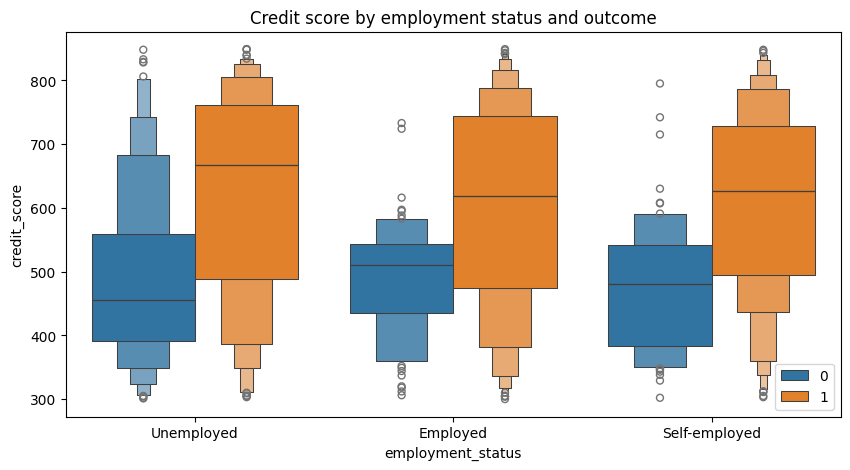

In [37]:
plt.figure(figsize=(10, 5))
sns.boxenplot(data=df, x="employment_status", y="credit_score", hue="loan_approved")
plt.legend(loc="lower right")
plt.title("Credit score by employment status and outcome")
plt.show()

## 2.3 Categorical Scatterplots

### 2.3.1 stripplot

<Axes: xlabel='employment_status', ylabel='credit_score'>

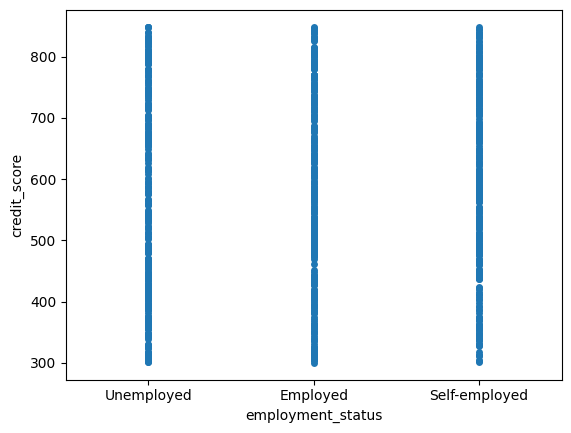

In [43]:
sns.stripplot(data=df, x="employment_status", y="credit_score", jitter=False)

Huh???? What information can we get from there? Probably nothing. Let's add
 jitter and see again

<Axes: xlabel='employment_status', ylabel='credit_score'>

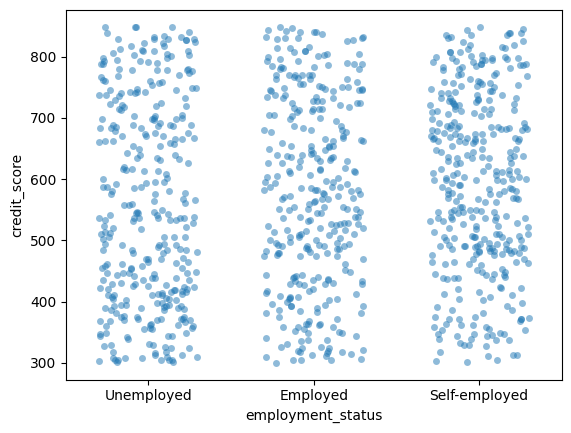

In [58]:
sns.stripplot(data=df, x="employment_status", y="credit_score", jitter=0.3, alpha=0.5)
# jitter adjusts the width of the sideways spread
# alpha controles trasparency (overlapping dots are forming darker areas)

Anna, thank you very much. What exactly are we looking at?????



*   Each cloud stretches from ~300 to ~850 credit score --> each group have applicants with a broad range of credit scores


Remeber Hue? How about we use this parameter to try to find out who gets more oftenly approved?


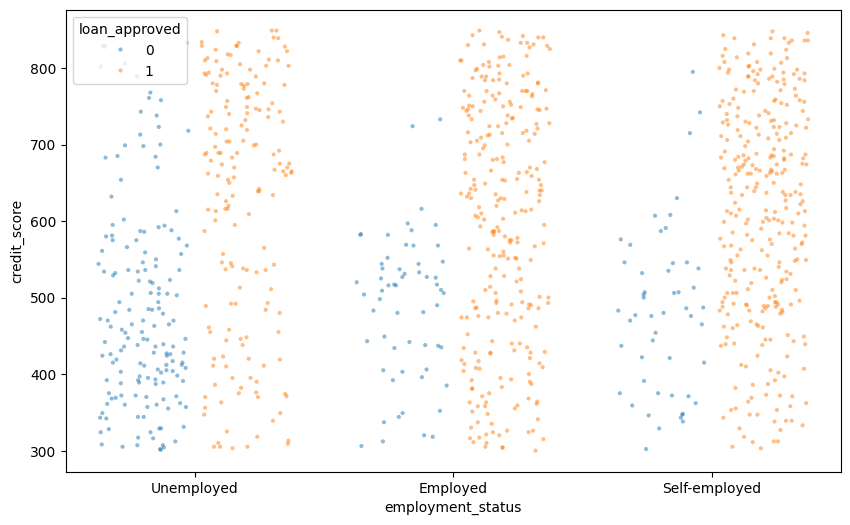

In [66]:
plt.figure(figsize=(10, 6))
sns.stripplot(data=df, x="employment_status", y="credit_score",
              hue="loan_approved",
              size=3,        # smaller dots
              alpha=0.5,     # transparency: overlaps show as darker areas
              jitter=0.35,   # wider sideways spread
              dodge=True)    # approved and rejected in separate columns
plt.show()

AHA!!!! Rejected applicants are BOTTOM HEAVY --> low credit score heavily affects loan borrowing rejection decison

### 2.3.2 swarmplot `sns.swarmplot()`

arranges the points so that they **don't overlap**, which shows the shape of the distribution. (It is slow for big datasets, so we use a random **sample** of 300 rows.

<Axes: xlabel='employment_status', ylabel='credit_score'>

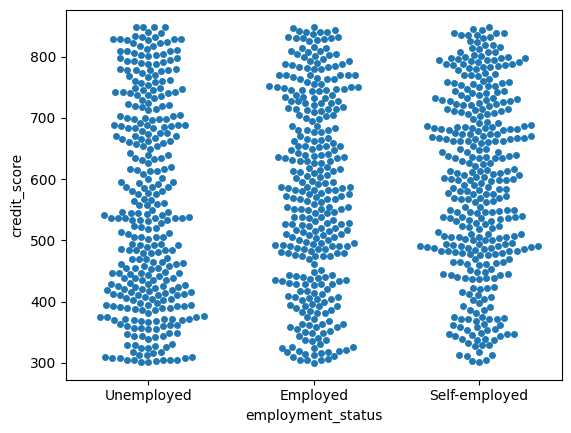

In [71]:
sns.swarmplot(data=df, x="employment_status", y="credit_score")

---
**Your turn**: create a sawrmplot comparing the spread of `annual_income` among people with `existing_loans_count`, groupped by `loan_approved` decision

In [83]:
plt.figure(figsize=(10, 6))
sns.____(data=df,
              x="_____",
              y="_____",
              hue="______",
              dodge=___)    # approved and rejected in separate columns
plt.show()

AttributeError: module 'seaborn' has no attribute '____'

<Figure size 1000x600 with 0 Axes>

---

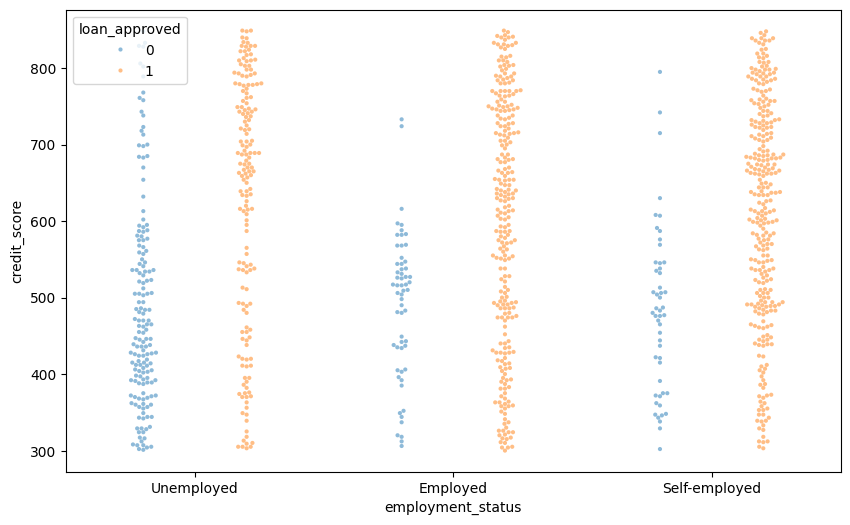

In [69]:
plt.figure(figsize=(10, 6))
sns.swarmplot(data=df, x="employment_status", y="credit_score",
              hue="loan_approved",
              size=3,        # smaller dots
              alpha=0.5,     # transparency: overlaps show as darker areas
              dodge=True)    # approved and rejected in separate columns
plt.show()

## 2.4 Categorical Frankenstein monster: Mixing categorical scatterplots and distributions

You can draw the plots on the same axis to enchance one another. For example, let's combine boxplots and stripplots for the marital status and loan amount

/tmp/ipykernel_5533/2970778347.py:3: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:lightgrey'` for the same effect.

  sns.boxplot(data=df, x="marital_status", y="loan_amount", color="lightgrey", hue="loan_approved")


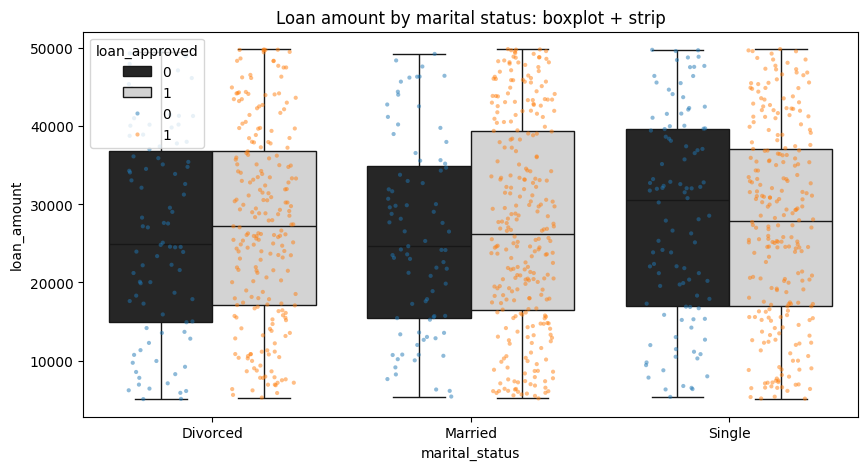

In [198]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="marital_status", y="loan_amount", color="lightgrey", hue="loan_approved")
sns.stripplot(data=df, x="marital_status", y="loan_amount", hue="loan_approved", alpha=0.5, jitter=0.25, size=3, dodge=True)

plt.title("Loan amount by marital status: boxplot + strip")
plt.show()

---
**Your turn**: Combine `violinplot` and `swarmplot` to check the distribution of `credit_score` by `employment_status`, group everything by `loan_approved`.

* For violinplot set colour to `white`
* For swarmplot set palette to `Paired`

/tmp/ipykernel_5533/1517285158.py:2: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:white'` for the same effect.

  sns.violinplot(data=df, x="employment_status", y="credit_score", color="white", hue="loan_approved", inner=None)


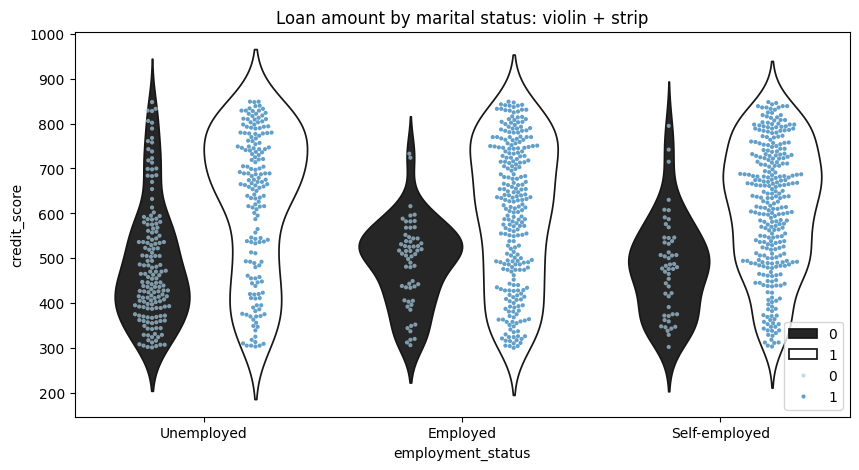

In [119]:
plt.figure(figsize=(10, 5))
sns.____(data=df, x="employment_status", y="____", color="____", hue="____", inner=None, cut=0)        # create a violin plot
____.____(data=df, x="_____", y="____", hue="_____", palette="_____", alpha=0.7, size=3, dodge=True)   # create a swarmplot

plt.title("Credit Score by employment status: violin + swarm")
plt.legend(loc="lower right")
plt.show()

---

# 3 WORKING WITH DATA DISTRIBUTIONS

The **distribution** of a variable tells us **which values occur and how often**. Looking at distributions answers questions like: *What is the range? Where is the centre? Is it symmetric or skewed? Are there outliers? Does it have one peak or several?*

## 3.1 Histograms `sns.histplot()`
A histogram divides the range of values into **bins** (intervals) and draws a bar showing **how many observations fall in each bin**

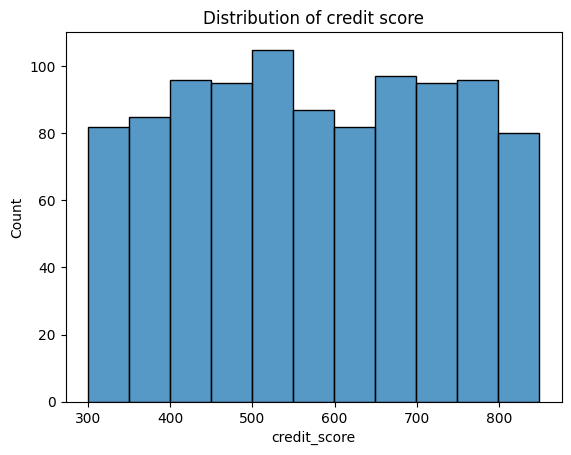

In [120]:
sns.histplot(data=df, x="credit_score")
plt.title("Distribution of credit score")
plt.show()

The number of bins changes how the histogram looks. Too few bins hide details; too many make it noisy. Try `bins=` or `binwidth=`

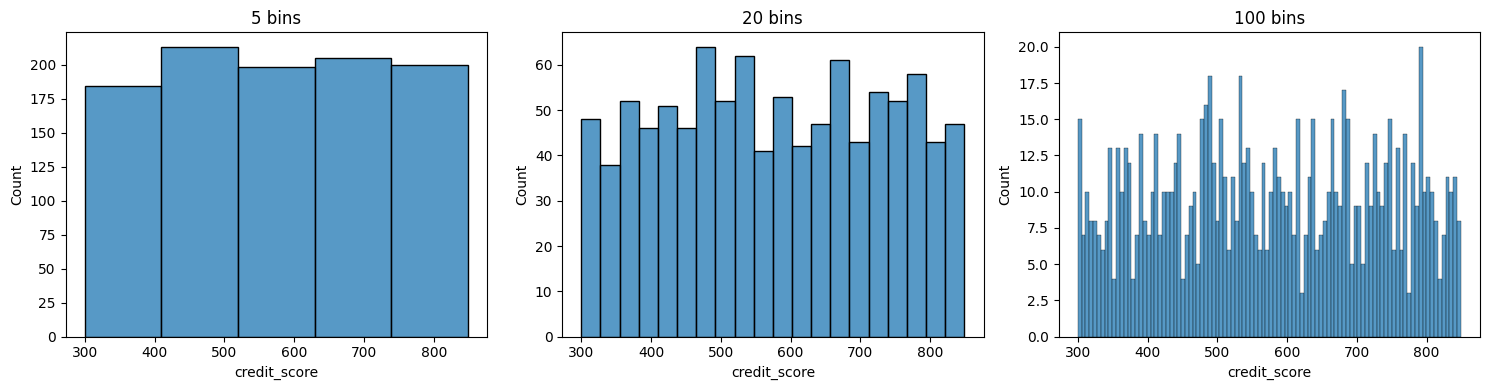

In [121]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data=df, x="credit_score", bins=5, ax=axes[0]).set_title("5 bins")
sns.histplot(data=df, x="credit_score", bins=20, ax=axes[1]).set_title("20 bins")
sns.histplot(data=df, x="credit_score", bins=100, ax=axes[2]).set_title("100 bins")
plt.tight_layout()
plt.show()

---
**Your turn**: Remeber hue? Use this parameter to create a hist plot to plot distribution of `annual_income` and group it by `loan_approved`)

<Axes: xlabel='annual_income', ylabel='Count'>

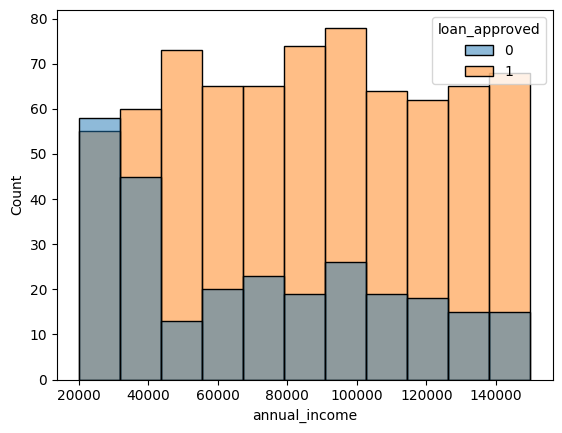

In [125]:
___.___(data=df, x="____", hue="___")


---

### 3.1.1 Combining the groups with `multiple=`

The `multiple=` parameter controls how the groups are combined:
* `"layer"` (default): drawn on top of each other
* `"stack"`: stacked on top of each other
* `"dodge"`: bars side by side
* `"fill"`: stacked and stretched to 100 %, showing the **proportion** of each group in each bin

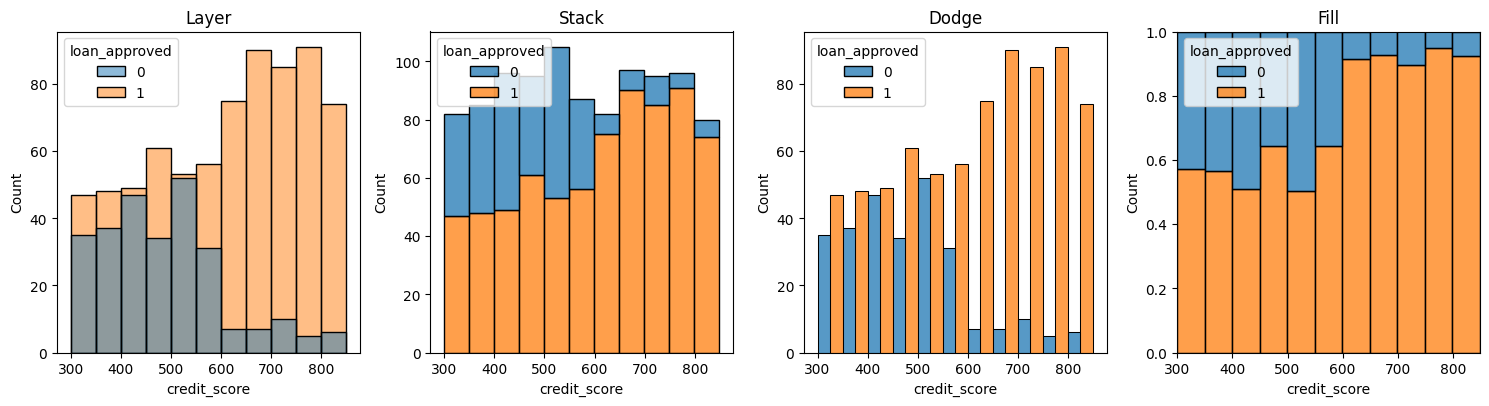

In [134]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
sns.histplot(ax=axes[0], data=df, x="credit_score", hue="loan_approved", multiple="layer") # layer parameter

# Your turn: adjust the rest of the plots
sns.histplot(ax=axes[1], data=df, x="credit_score", hue="loan_approved", multiple="stack") # stack
sns.histplot(ax=axes[2], data=df, x="credit_score", hue="loan_approved", multiple="___") # dodge
___.___(ax=axes[3], data=df, x="credit_score", hue="loan_approved", ___ ="___")  # fill

plt.tight_layout()
axes[0].set_title("Layer")
axes[1].set_title("Stack")
axes[2].set_title("Dodge")
axes[3].set_title("Fill")
plt.show()

The `"fill"` version (bottom right) is the most useful for our first question: it shows the **share of rejected applications in each credit-score bin**

## 3.2 Kernel Density Plot `sns.kdeplot()`

A **KDE** draws a **smooth curve** instead of bars; think of it as a "smoothed histogram". Add it to a histogram with `kde=True`, or draw it on its own with `sns.kdeplot()`.

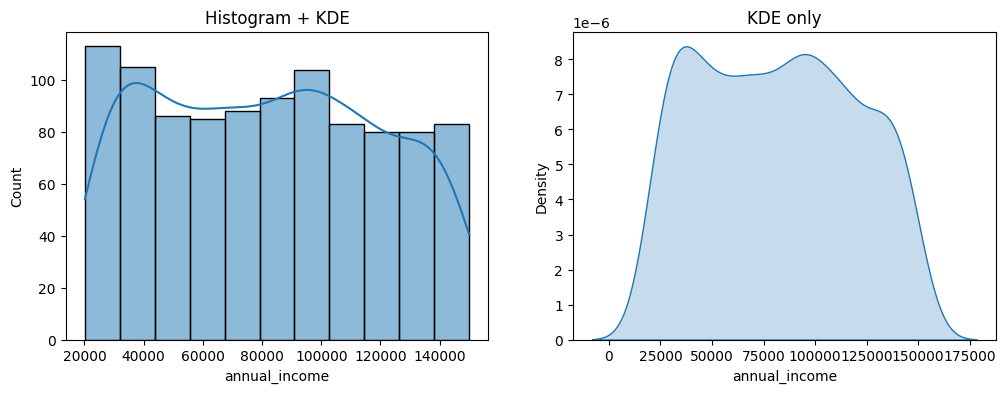

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="annual_income", kde=True, ax=axes[0])
axes[0].set_title("Histogram + KDE")

sns.kdeplot(data=df, x="annual_income", fill=True, ax=axes[1])
axes[1].set_title("KDE only")
plt.show()

Note: KDE curves "leak" beyond the real minimum and maximum of the data (here, below 20,000 and above 150,000) because of the smoothing. This makes a flat distribution look as if it had rounded "shoulders". You can limit this with `cut=0`

## 3.3 Empirical cumulative distribution `sns.ecdfplot()`


An **ECDF** shows, for every value *x*, the **proportion of observations that are less than or equal to *x***. It has no bins and no smoothing, so it hides nothing.
* A curve that rises **steadily in a straight line** means the values are spread **evenly** (uniform).
* A normal distribution gives an **S-shaped** ECDF.
* When two curves are far apart, the groups differ.

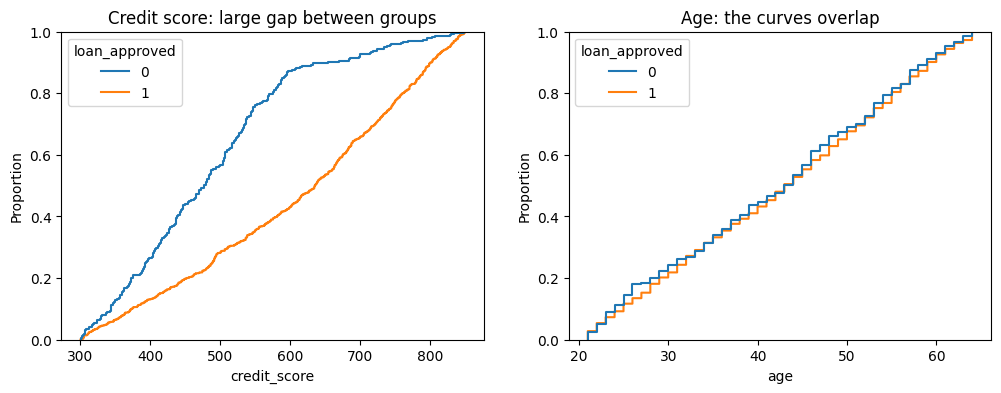

In [136]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.ecdfplot(ax=axes[0], data=df, x="credit_score", hue="loan_approved")
axes[0].set_title("Credit score: large gap between groups")

sns.ecdfplot(ax=axes[1], data=df, x="age", hue="loan_approved")
axes[1].set_title("Age: the curves overlap")
plt.show()

How to interpret: For **credit score** the curves are far apart, so approved and rejected applicants have very different scores. For **age** the curves are almost on top of each other, so age makes **no difference**. This is a neat way to judge the importance of a factor

More on ecdf function and when to use it: https://www.visualizing.org/ecdf-plot

*Note from Anna: I rarely saw people actually using ecdf in exploratory data analysis, however statistitisans use them a lot. and they start to gain popularity in the data science field too so oit is important to mention them*

## 3.4 Bivariative distributions
This is the distribution of two *continuous* variables at once. It answers: *which combinations of values are common? (e.g. “low credit score and low income”)*.

With `x` *and* `y`, `histplot` and `kdeplot` show **bivariate** distributions as a coloured grid or contour lines. Think of it as if you was looking above the histogram.

* **Bivariate histogram `histplot`**: the plane is cut into a grid of rectangles, and each one’s colour shows how many applicants fall in it. Darker means more. It’s like a scatter plot turned into a heatmap.

* **Bivariate KDE `kdeplot`**: the smooth version, drawn as contour lines, like a hill on a map. The innermost ring is the “peak”, where points are most crowded; each outer ring encloses less crowded areas


Let's try to plot the connection between the `annual_income` and `credit_score` exclusiely for the `rejected` applicants

### 3.4.1 bivariative `histplot`

In [159]:
rejected = df[df["loan_approved"] == 0] # dataframe that includes only the rows where the loan got rejected
accepted = df[df["loan_approved"] == 1] # dataframe that includes only the rows where loan got accepted (we will need it later)

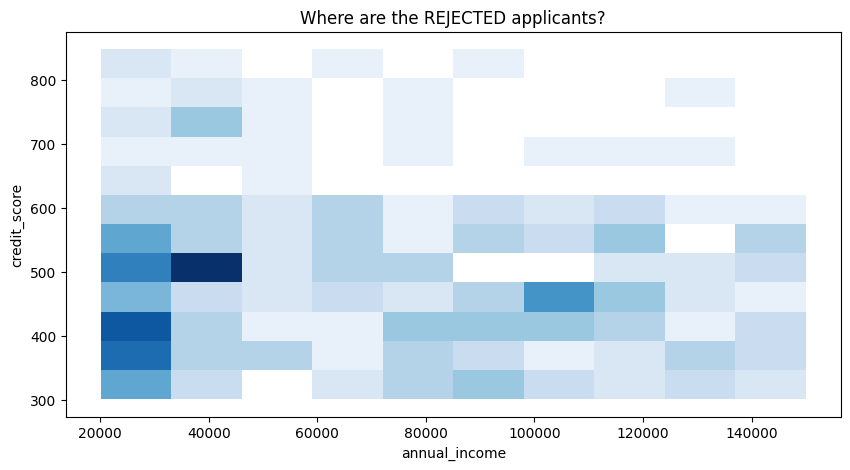

In [160]:
plt.figure(figsize=(10, 5))

sns.histplot(data=rejected, x="annual_income", y="credit_score",
            cmap="Blues")    # gradient colour map (areas wil higher density are darker)

plt.title("Where are the REJECTED applicants?")
plt.show()

Huh????? I mean, we can say that combination of low credit score and low credit income is not very good. But it is really hard to say something else from here

This is why let's smooth all kernels (squares) using `kdeplot`and see what will happen


### 3.4.2 bivariative `kdeplot`

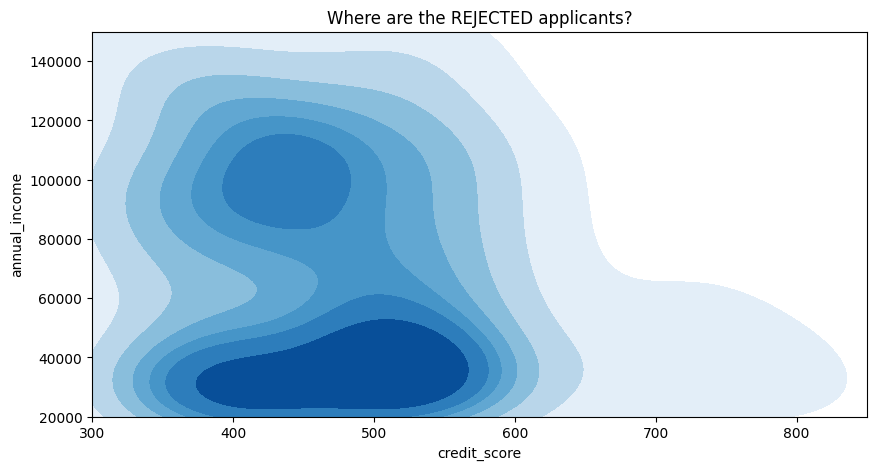

In [162]:
plt.figure(figsize=(10, 5))

sns.kdeplot(data=rejected, x="credit_score", y="annual_income",
            fill=True,                               # fill the space between the lines
            cmap="Blues",                            # gradient colour map (areas with higher density are darker)
            levels=8,                                # how many rings should be displayed in total
            thresh=0.05,                             # where the data drawing starts
            clip=((300, 850), (20000, 150000)))

plt.title("Where are the REJECTED applicants?")
plt.show()

---
**Your turn**: complete the code to include `kdeplot` representing the connection between the `annual_income` and `credit_score` for the `accepted` applicants. Use `Oranges` cmap

AttributeError: 'Axes' object has no attribute '___'

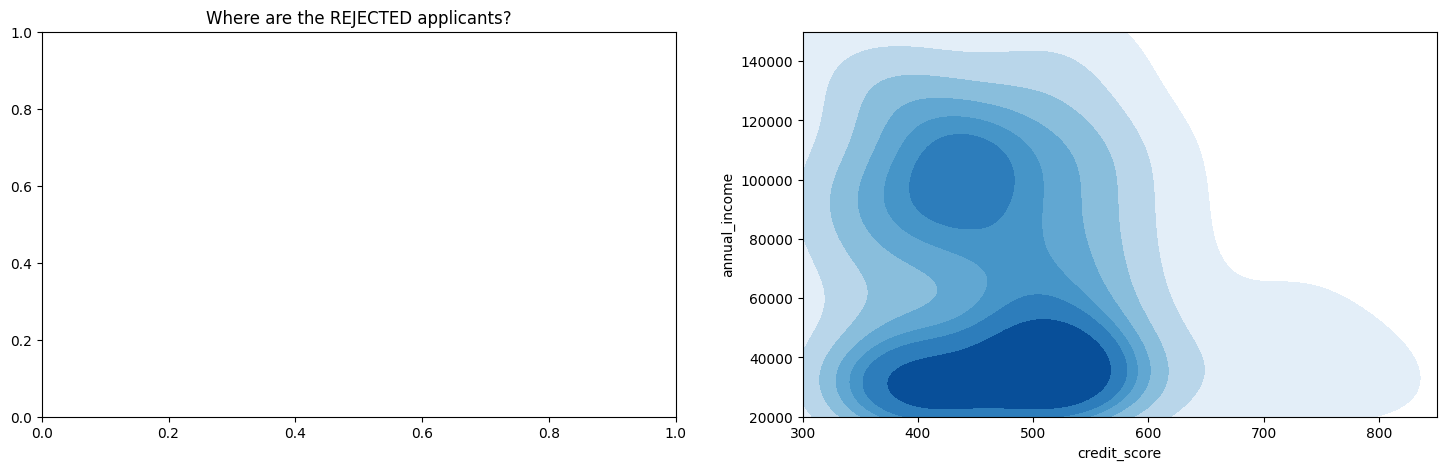

In [167]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))


sns.kdeplot(data=rejected, x="credit_score", y="annual_income",
            fill=True,                               # fill the space between the lines
            cmap="Blues",                            # gradient colour map (areas with higher density are darker)
            levels=8,                                # how many rings should be displayed in total
            thresh=0.05,                             # where the data drawing starts
            clip=((300, 850), (20000, 150000)))

axes[0].set_title("Where are the REJECTED applicants?")

___.___(data=___, x="___", y="___",
            fill=True,
            cmap="___",
            levels=8,
            thresh=0.05,
            clip=((300, 850), (20000, 150000)))

axes[1].set_title("Where are the ACCEPTED applicants?")

---

## 3.5 Continuous Frankenstein `sns.jointgrid()` to plot multiple distributions

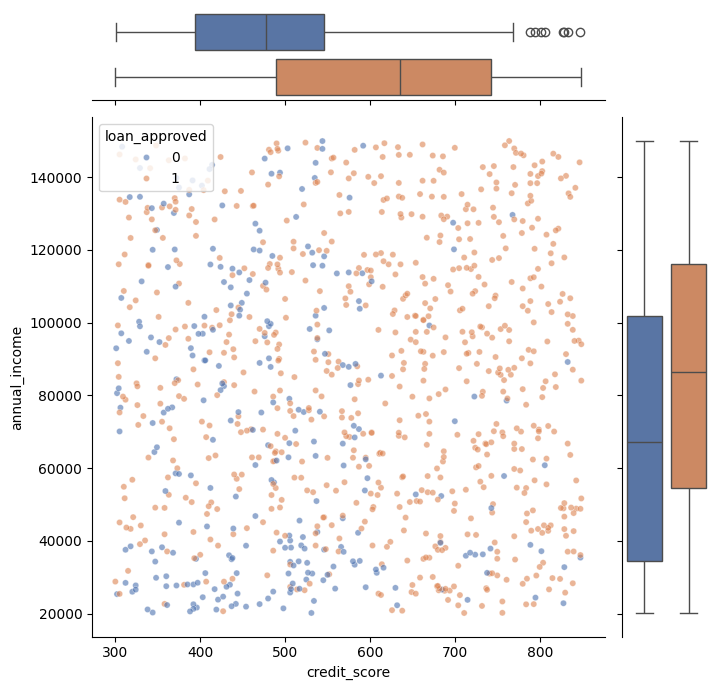

In [196]:
g = sns.JointGrid(data=df, x="credit_score", y="annual_income", height=7)


pal = {0: "#4C72B0", 1: "#DD8452"}          # 0 = rejected (blue), 1 = approved (orange)

# Middle: scatter plot coloured by outcome
g.plot_joint(sns.scatterplot, hue=df["loan_approved"], palette=pal, alpha=0.6, s=20)

# Margins: orient tells seaborn which way the boxes go
sns.boxplot(data=df, x="credit_score", y="loan_approved", hue="loan_approved",
            palette=pal, orient="h", ax=g.ax_marg_x, legend=False)   # horizontal boxes
sns.boxplot(data=df, y="annual_income", x="loan_approved", hue="loan_approved",
            palette=pal, orient="v", ax=g.ax_marg_y, legend=False)   # vertical boxes

plt.show()

More to read on `sns.jointplot`: https://seaborn.pydata.org/generated/seaborn.jointplot.html

# 4 CONCLUSIONS
Phew! that was a bit hard but we made it!!! We did cover a little bit pandas and a lot with data visualisation.

Thetre is more to cover! Check this seaborn tutorial (especially visualising statistical relationships) https://seaborn.pydata.org/tutorial/introduction.html

let's try to summarise our findings
## Which factors have the most and least effect on loan approval?

| Effect | Factor | Evidence |
|---|---|---|
| **Strongest** | **Credit score** | Higher rejection rate with the lower credit score. Significantly higher (85%) chance of approval with credit score above 600 (r = +0.35, moderate positive correlation) |
| **Strongest** | **Number of dependents** | Approval is really high with 0–2 dependents, drops significantly with 3+ (r = −0.37, moderate negative correlation) |
| **Strong** | **Existing loans** | Approval rate drops significantly with with 3+ existing loans (r = −0.32, moderate negative correlation) |
| **Strong** | **Employment status** |unemployed are more likely to get rejections rather employed and self-employed |
| **Moderate** | **Annual income** | Only the lowest incomes are penalised, the higher the income, the smaller the difference approval rate (r = +0.18, weak positive correlation) |
| **Very Weak/none** | Marital status | Very similar approval rate, not significant |
| **None** | Gender | Very similar approval rate, not significant |
| **None** | Age | ECDFs and box plots of approved/rejected overlap |
| **None** | Loan amount | box plots identical, no correlation |

The data is **NOT** normally distributed. It follows **uniform** distribution

# Appendix: Additional Support Material

More practice with pandas: https://leetcode.com/studyplan/introduction-to-pandas/

Seaborn tutorial: https://seaborn.pydata.org/tutorial/introduction.html

Good seaborn tutorial on youtube: https://www.youtube.com/watch?v=S42REDd4ne4